### **Setup (only for this file)**
These lines repeat what Parts 1 to 3 already do: the setup, the functions of Part 2, the 12 temporal splits, the candidates of 21.1 and the final set of Part 3 (28.3). They are removed when Part 4 is joined to the main notebook.

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

train_path=os.path.join("..","data","raw","train.csv")
clientes_path=os.path.join("..","data","raw","clientes.csv")

df_train= pd.read_csv(train_path,index_col="ID",sep=",")
df_clientes = pd.read_csv(clientes_path, sep=",")

target_col = "repeat_purchase_90d"
var_groups = {
    "Current transaction (financial)": ["Total a Pagar", "Total Bruto", "Total Liquido", "Total Imp_", "Total Portes",
                                        "Total Desc_ Global", "Total Desc_ Linha", "Custo"],
    "Current transaction (operational)": ["N_ Detalhes", "invoice_count_current_purchase"],
    "Customer historical summary": ["customer_tenure_days", "prior_purchase_count", "prior_total_spend",
                                    "prior_mean_purchase_value", "prior_std_purchase_value",
                                    "prior_min_purchase_value", "prior_max_purchase_value"],
    "Customer cadence & gaps": ["days_since_previous_purchase", "prior_mean_gap_days", "prior_std_gap_days"],
    "Rolling windows (RFM)": ["purchase_count_30d", "spend_30d", "purchase_count_90d", "spend_90d",
                              "purchase_count_180d", "spend_180d", "purchase_count_365d", "spend_365d"],
}

# recover_values of 3.6.7
def recover_values(frame):
    """Fills the cells that can be computed exactly from other columns of the same row (3.6.1 and 3.6.7)."""
    out = frame.copy()
    count, tenure = out["prior_purchase_count"], out["customer_tenure_days"]
    out["prior_mean_purchase_value"] = out["prior_total_spend"] / count.replace(0, np.nan)

    days, gap = out["days_since_previous_purchase"].copy(), out["prior_mean_gap_days"].copy()
    fill = days.isna() & (count == 1)
    out.loc[fill, "days_since_previous_purchase"] = tenure[fill]
    fill = days.isna() & (count >= 2) & gap.notna()
    out.loc[fill, "days_since_previous_purchase"] = (tenure - gap * (count - 1))[fill]
    fill = gap.isna() & (count >= 2) & days.notna()
    out.loc[fill, "prior_mean_gap_days"] = ((tenure - days) / (count - 1))[fill]

    fill = out["spend_365d"].isna() & (out["purchase_count_365d"] == 0)
    out.loc[fill, "spend_365d"] = 0.0
    fill = out["spend_365d"].isna() & (out["purchase_count_365d"] == out["purchase_count_180d"])
    out.loc[fill, "spend_365d"] = out.loc[fill, "spend_180d"]
    fill = out["spend_365d"].isna() & (out["purchase_count_365d"] == count)
    out.loc[fill, "spend_365d"] = out.loc[fill, "prior_total_spend"]

    fill = out["prior_max_purchase_value"].isna() & (count == 1)
    out.loc[fill, "prior_max_purchase_value"] = out.loc[fill, "prior_total_spend"]
    fill = out["prior_max_purchase_value"].isna() & (count == 2)
    out.loc[fill, "prior_max_purchase_value"] = (out["prior_total_spend"] - out["prior_min_purchase_value"])[fill]
    return out

In [2]:
import warnings
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, FunctionTransformer,
                                   StandardScaler, MinMaxScaler, RobustScaler)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score
from sklearn.exceptions import ConvergenceWarning

# without scaling the solver can stop at its limit of iterations. We look at this in section 18, so we hide the warning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [3]:
def signed_log(X):
    """log1p that keeps the sign. For values >= 0 it is the same as log1p, and it also works
    on the negative impossible values of the option "keep as is" (13.4)."""
    return np.sign(X) * np.log1p(np.abs(X))


class Winsorizer(BaseEstimator, TransformerMixin):
    """Clips each column to its 1% and 99% quantiles, learned on the train rows."""
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.low_ = np.nanquantile(X, 0.01, axis=0)
        self.high_ = np.nanquantile(X, 0.99, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)


def make_preprocessor(log_cols, plain_cols, cat_cols, flag_cols=(), num_fill="median", indicators=False,
                      cat_fill="Missing", outliers="log1p", encoder="onehot", min_frequency=None, scaler="standard"):
    """Layer B: the steps that learn something from the data (medians, levels, scales).
    Inside a Pipeline they are fitted only on the train rows of each split."""
    scalers = {"standard": StandardScaler, "minmax": MinMaxScaler, "robust": RobustScaler}

    def numeric_steps(long_tail):
        if num_fill == "zero":
            steps = [("impute", SimpleImputer(strategy="constant", fill_value=0, add_indicator=indicators))]
        else:
            steps = [("impute", SimpleImputer(strategy=num_fill, add_indicator=indicators))]
        if long_tail and outliers == "log1p":
            steps.append(("log", FunctionTransformer(signed_log)))
        elif long_tail and outliers == "winsorize":
            steps.append(("winsorize", Winsorizer()))
        if scaler in scalers:
            steps.append(("scale", scalers[scaler]()))
        return Pipeline(steps)

    # categories: missing -> "Missing" (or the most frequent level), then encoding
    if cat_fill == "Missing":
        cat_steps = [("impute", SimpleImputer(strategy="constant", fill_value="Missing"))]
    else:
        cat_steps = [("impute", SimpleImputer(strategy="most_frequent"))]
    if encoder == "onehot" and min_frequency is None:
        cat_steps.append(("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)))
    elif encoder == "onehot":
        cat_steps.append(("encode", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency,
                                                  sparse_output=False)))
    else:
        cat_steps.append(("encode", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)))
        if scaler in scalers:
            cat_steps.append(("scale", scalers[scaler]()))

    parts = [("log", numeric_steps(long_tail=True), list(log_cols)),       # money, counts and days (long tails)
             ("plain", numeric_steps(long_tail=False), list(plain_cols)),  # columns that can be negative, or ratios
             ("cat", Pipeline(cat_steps), list(cat_cols)),
             ("flags", "passthrough", list(flag_cols))]                    # 0/1 columns
    return ColumnTransformer([p for p in parts if len(p[2]) > 0])


def temporal_scores(frame, columns, recipe, row_filter=None, metric="ap"):
    """One score per fold: the instrument is fitted on the train rows and scored on the validation block."""
    used = columns["log_cols"] + columns["plain_cols"] + columns["cat_cols"] + columns["flag_cols"]
    scores = []
    for train_idx, val_idx in folds:
        train, val = frame.loc[train_idx], frame.loc[val_idx]
        if row_filter is not None:
            train = row_filter(train)   # rows are only removed from the train side, never from validation
        pipe = Pipeline([("prep", make_preprocessor(**columns, **recipe)),
                         ("model", LogisticRegression(max_iter=3000))])
        pipe.fit(train[used], train[target_col])
        prob = pipe.predict_proba(val[used])[:, 1]
        if metric == "ap":
            scores.append(average_precision_score(val[target_col], prob))
        elif metric == "f1":
            scores.append(f1_score(val[target_col], prob >= 0.5))
        else:
            scores.append((prob >= 0.5).mean())   # share of rows predicted as 1
    return np.array(scores)


def compare(results, reference):
    """Mean AP of each option and its difference to the reference, fold by fold (paired)."""
    rows = {}
    for name, scores in results.items():
        diff = scores - results[reference]
        sem = diff.std(ddof=1) / np.sqrt(len(diff))
        if name == reference:
            verdict = "reference"
        elif abs(diff.mean()) <= 2 * sem:
            verdict = "inside the noise"
        else:
            verdict = "better" if diff.mean() > 0 else "worse"
        rows[name] = {"AP": round(scores.mean(), 4), "difference": round(diff.mean(), 4), "SEM": round(sem, 4),
                      "better in": f"{(diff > 0).sum()}/{len(diff)}", "verdict": verdict}
    return pd.DataFrame(rows).T


def blank_impossible(frame):
    """Impossible values of 3.6 -> missing. It works row by row, so it learns nothing from the other rows."""
    out = frame.copy()
    count = out["prior_purchase_count"]
    # 3.6.1 to 3.6.3: 1e9, negative values, means bigger than the biggest purchase, spend_365d bigger than the prior spend
    mean = out["prior_mean_purchase_value"]
    out.loc[(mean < 0) | (mean >= 1e8) | (mean > out["prior_max_purchase_value"] + 0.01), "prior_mean_purchase_value"] = np.nan
    spend = out["spend_365d"]
    out.loc[(spend < 0) | (spend >= 1e8) | (spend > out["prior_total_spend"] + 0.01), "spend_365d"] = np.nan
    for col in ["days_since_previous_purchase", "prior_mean_gap_days"]:
        out.loc[out[col] < 0, col] = np.nan
    # 3.6.6: biggest purchase above its limit
    max_limit = out["prior_total_spend"] - (count - 1) * out["prior_min_purchase_value"]
    out.loc[(count >= 1) & (out["prior_max_purchase_value"] > max_limit + 0.01), "prior_max_purchase_value"] = np.nan
    return out


def add_features(frame):
    """New variables, built row by row from the columns of the same purchase."""
    out = frame.copy()
    months = out["customer_tenure_days"] / 30
    out["bought_in_90d"] = (out["purchase_count_90d"] > 0).astype(int)
    out["rhythm_ratio"] = out["days_since_previous_purchase"] / out["prior_mean_gap_days"].replace(0, np.nan)
    out["purchase_rate"] = out["prior_purchase_count"] / (months + 1)
    out["spend_per_month"] = out["prior_total_spend"] / (months + 1)
    out["avg_basket_365d"] = out["spend_365d"] / out["purchase_count_365d"].replace(0, np.nan)
    out["spend_acceleration"] = out["spend_30d"] / (out["spend_90d"] + 1)
    out["margin_ratio"] = (out["Total Liquido"] - out["Custo"]) / (out["Total Liquido"] + 1)
    out["discount_intensity"] = (out["Total Desc_ Linha"] + out["Total Desc_ Global"]) / (out["Total Bruto"] + 1)
    out["value_vs_habit"] = ((out["Total a Pagar"] - out["prior_mean_purchase_value"])
                             / out["prior_std_purchase_value"].replace(0, np.nan))
    return out


def prepare_data(frame, clientes):
    """Layer A: every step that works row by row. The same function will be used on test.csv."""
    out = frame.copy()
    out["purchase_date"] = pd.to_datetime(out["purchase_date"])
    out = blank_impossible(out)
    out = recover_values(out)          # 3.6.7
    out["is_first_purchase"] = (out["prior_purchase_count"] == 0).astype(int)
    out = out.join(clientes.set_index("customer_id")[["country_or_region", "commercial_region", "island",
                                                      "municipality", "postal_area"]],
                   on="customer_id", validate="many_to_one")
    out["incomplete_address"] = (out["municipality"].isna() & out["postal_area"].isna()).astype(int)
    out = add_features(out)
    return out

In [4]:
# 12.1 and 12.2: rows without the empty ones, development rows and the 12 temporal splits
empty_rows = df_train.drop(columns=["customer_id", target_col]).isna().all(axis=1)
df_model = prepare_data(df_train.loc[~empty_rows], df_clientes)
is_dev = df_model["purchase_date"] < "2024-01-01"
dev = df_model.loc[is_dev]
block_starts = pd.date_range("2018-01-01", "2023-07-01", freq="6MS")
folds = []
for start in block_starts:
    end = start + pd.DateOffset(months=6)
    train_idx = dev.index[dev["purchase_date"] < start - pd.Timedelta(days=90)]
    val_idx = dev.index[(dev["purchase_date"] >= start) & (dev["purchase_date"] < end)]
    folds.append((train_idx, val_idx))

# 21.1: the candidates and the recipe that Part 2 hands to Part 3
final_columns = {
    "log_cols": [
        "Total a Pagar", "Total Bruto", "Total Liquido", "Total Imp_", "Total Portes",
        "Total Desc_ Global", "Total Desc_ Linha", "Custo", "N_ Detalhes",
        "invoice_count_current_purchase", "customer_tenure_days", "prior_purchase_count",
        "prior_total_spend", "prior_mean_purchase_value", "prior_std_purchase_value",
        "prior_min_purchase_value", "prior_max_purchase_value", "days_since_previous_purchase",
        "prior_mean_gap_days", "prior_std_gap_days", "purchase_count_30d", "spend_30d",
        "purchase_count_90d", "spend_90d", "purchase_count_180d", "spend_180d", "purchase_count_365d",
        "spend_365d", "rhythm_ratio", "purchase_rate", "spend_per_month", "avg_basket_365d"],
    "plain_cols": [
        "random_noise", "spend_acceleration", "margin_ratio", "discount_intensity", "value_vs_habit"],
    "cat_cols": [
        "payment_type", "salesperson", "commercial_zone", "transport_method", "warehouse",
        "document_series", "country_or_region", "commercial_region", "island"],
    "flag_cols": [
        "is_first_purchase", "incomplete_address"],
}
final_recipe = {"num_fill": "median", "indicators": False, "cat_fill": "Missing", "outliers": "log1p", "encoder": "onehot", "min_frequency": 10, "scaler": "standard"}
feature_cols = final_columns["log_cols"] + final_columns["plain_cols"] + final_columns["cat_cols"] + final_columns["flag_cols"]
print(f"Rows: {len(df_model):,} | Development: {is_dev.sum():,} | Candidates: {len(feature_cols)}")

Rows: 6,469 | Development: 5,634 | Candidates: 48


In [5]:
# 28.3: the final set of Part 3
selected = ["Total Bruto", "prior_max_purchase_value", "prior_std_gap_days", "purchase_count_90d", "purchase_count_365d",
            "purchase_rate", "avg_basket_365d", "margin_ratio", "discount_intensity", "salesperson", "transport_method",
            "is_first_purchase"]
selected_columns = {group: [c for c in cols if c in selected] for group, cols in final_columns.items()}
print(f"Final set of Part 3: {len(selected)} variables")

Final set of Part 3: 12 variables


### **29. Modelling: The Plan**

Part 4 builds the model that predicts `repeat_purchase_90d` for test.csv. The guidelines ask for a model and its evaluation with the F1 of class 1, the metric of the competition. The professor said that ideally we build only one model, so we keep the comparison short: **two models**, chosen for what they bring.
* **Logistic regression**: the instrument of Parts 2 and 3. In the EDA the strongest relations were monotonic (section 7), and with `log1p` and the scaler a linear model can follow them. It is simple and we can read its coefficients.
* **Gradient boosting** (`HistGradientBoostingClassifier`): usually the strongest model for tables like ours. Its trees can find what a linear model can not, like breaks (the 90 days of 7.3) and interactions between variables.

The plan follows the rules of the previous parts:
* every option is fitted on the train rows of the same 12 temporal splits and scored on the validation blocks (12.2);
* the models and their settings are compared with the AP, as in Parts 2 and 3, because it does not depend on the threshold;
* then the threshold is chosen for the F1 (2.3), with the predictions of the 12 blocks;
* the holdout (2024 and 2025), never used until now, gives the honest check of the chosen model (34);
* the final model learns from all the rows of train.csv and predicts test.csv (35).

`split_probs` gives the probabilities of each validation block, and `board` puts the options side by side: the AP with `compare` (paired, with the SEM) and the best F1 that each option can reach.

In [6]:
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import confusion_matrix


def split_probs(model, columns):
    """The probabilities of each validation block, from the pipeline fitted on the train rows of its split."""
    probs = []
    for train_idx, val_idx in folds:
        pipe = Pipeline([("prep", make_preprocessor(**columns, **final_recipe)), ("model", clone(model))])
        pipe.fit(df_model.loc[train_idx, feature_cols], df_model.loc[train_idx, target_col])
        probs.append(pipe.predict_proba(df_model.loc[val_idx, feature_cols])[:, 1])
    return probs


y_blocks = [df_model.loc[val_idx, target_col].to_numpy() for _, val_idx in folds]
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)


def block_ap(probs):
    """AP of each validation block, as in Parts 2 and 3."""
    return np.array([average_precision_score(y, p) for y, p in zip(y_blocks, probs)])


def f1_curve(probs):
    """F1 of class 1 of the 12 blocks together, for each threshold."""
    y_all, p_all = np.concatenate(y_blocks), np.concatenate(probs)
    return pd.Series([f1_score(y_all, p_all >= t) for t in thresholds], index=thresholds)


def board(probs_by_name, reference):
    """compare (AP, paired) plus the best F1 that each option can reach with its own threshold."""
    table = compare({name: block_ap(p) for name, p in probs_by_name.items()}, reference)
    table["best F1"] = [round(f1_curve(p).max(), 4) for p in probs_by_name.values()]
    return table


floor_f1 = f1_score(np.concatenate(y_blocks), np.ones(sum(len(y) for y in y_blocks)))
print(f"F1 of always predicting 1 in the 12 blocks: {floor_f1:.3f}")

F1 of always predicting 1 in the 12 blocks: 0.706


Always predicting 1 gives an F1 of 0.706 in the 12 blocks (2.3). This is the floor that every model has to beat.

### **30. Two Models, Two Sets of Variables**

First the two models with their default settings, each with the final set of Part 3 (28.3) and with all the 48 candidates. Part 3 chose the variables with a linear model, and in 28.4 we said that the trees should also try all the candidates.

In [7]:
models = {"logistic regression": LogisticRegression(max_iter=3000),
          "gradient boosting": HistGradientBoostingClassifier(random_state=44)}
variable_sets = {"final set": selected_columns, "all candidates": final_columns}

probs = {f"{m}, {s}": split_probs(model, columns) for m, model in models.items() for s, columns in variable_sets.items()}
board(probs, "logistic regression, final set")

,AP,difference,SEM,better in,verdict,best F1
"logistic regression, final set",0.8357,0.0,0.0,0/12,reference,0.7454
"logistic regression, all candidates",0.8347,-0.0011,0.0015,6/12,inside the noise,0.7370
"gradient boosting, final set",0.8194,-0.0163,0.0049,2/12,worse,0.7311
"gradient boosting, all candidates",0.8216,-0.0141,0.0033,2/12,worse,0.7302


With the default settings, gradient boosting is clearly **worse** than the logistic regression (about −0.015 of AP, with both sets of variables). The default trees are big (31 leaves) and learn fast, and with a few thousand train rows they learn noise. The logistic regression is a bit better with the final set than with all the candidates (inside the noise), as Part 3 measured. So both models need tuning before we compare them.

### **31. Tuning**

Each model is tuned on the same 12 splits, with the AP. We use small grids: Parts 2 and 3 showed that this data rewards simple models, and every extra setting tried on the same blocks makes the best result a bit more optimistic.

#### **31.1. Logistic Regression**

In [8]:
# C is the inverse of the strength of the L2 penalty: a small C gives smaller coefficients
C_grid = [0.01, 0.03, 0.1, 0.3, 1, 3]
lr_probs = {C: split_probs(LogisticRegression(C=C, max_iter=3000), selected_columns) for C in C_grid}
lr_table = pd.DataFrame({"AP": [block_ap(p).mean() for p in lr_probs.values()],
                         "best F1": [f1_curve(p).max() for p in lr_probs.values()]}, index=pd.Index(C_grid, name="C")).round(4)
best_C = float(lr_table["AP"].idxmax())
print(f"Best C: {best_C}")
lr_table

Best C: 0.1


,AP,best F1
C,,
0.01,0.8376,0.7447
0.03,0.8383,0.7454
0.10,0.8388,0.7446
0.30,0.8385,0.7455
1.00,0.8357,0.7454
3.00,0.8321,0.7446


The penalty changes the AP very little: all the values of C are within about 0.007, and the best is C = 0.1, a bit stronger than the default (C = 1). With 12 variables there is not much to penalize.

#### **31.2. Gradient Boosting**

In [9]:
# from the default (big trees, fast learning) to small trees that learn slowly
gb_grid = [dict(learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=20, max_iter=100),
           dict(learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=40, max_iter=200),
           dict(learning_rate=0.03, max_leaf_nodes=7, min_samples_leaf=80, max_iter=300),
           dict(learning_rate=0.03, max_leaf_nodes=4, min_samples_leaf=80, max_iter=400),
           dict(learning_rate=0.05, max_leaf_nodes=4, min_samples_leaf=150, max_iter=200)]
gb_probs, rows = {}, []
for i, settings in enumerate(gb_grid):
    model = HistGradientBoostingClassifier(**settings, l2_regularization=1.0, random_state=44)
    row = {"leaves": settings["max_leaf_nodes"], "learning rate": settings["learning_rate"],
           "min rows per leaf": settings["min_samples_leaf"], "trees": settings["max_iter"]}
    for s, columns in variable_sets.items():
        gb_probs[(i, s)] = split_probs(model, columns)
        row[f"AP, {s}"] = round(block_ap(gb_probs[(i, s)]).mean(), 4)
        row[f"best F1, {s}"] = round(f1_curve(gb_probs[(i, s)]).max(), 4)
    rows.append(row)
best_gb = max(gb_probs, key=lambda k: block_ap(gb_probs[k]).mean())
print(f"Best gradient boosting: settings {best_gb[0] + 1} with the {best_gb[1]}")
pd.DataFrame(rows, index=pd.Index(range(1, len(gb_grid) + 1), name="settings"))

Best gradient boosting: settings 4 with the all candidates


,leaves,learning rate,min rows per leaf,trees,"AP, final set","best F1, final set","AP, all candidates","best F1, all candidates"
settings,,,,,,,,
1,31,0.10,20,100,0.8191,0.7311,0.8207,0.7343
2,15,0.05,40,200,0.8283,0.7362,0.8274,0.7364
3,7,0.03,80,300,0.8356,0.7390,0.8348,0.7420
4,4,0.03,80,400,0.8380,0.7445,0.8402,0.7467
5,4,0.05,150,200,0.8367,0.7426,0.8379,0.7454


Smaller trees that learn slowly are much better: from the default (settings 1) to trees with only 4 leaves, a learning rate of 0.03 and at least 80 rows per leaf (settings 4), the AP goes from about 0.82 to about 0.84. A tree with 4 leaves can only combine two or three variables, so the best boosting is close to an additive model, the same kind of model as the logistic regression. This agrees with the EDA: the strong relations are monotonic and the variables add up. With small trees, gradient boosting is slightly better with all the candidates, so it keeps them.

### **32. Choosing the Model**

Now the best version of each model, side by side. We also try the mean of their probabilities: the two models make different mistakes (one is linear on 12 variables, the other uses small trees on 48), so their mean can be better than each one alone.

In [10]:
finalists = {"logistic regression": lr_probs[best_C], "gradient boosting": gb_probs[best_gb]}
finalists["average of the two"] = [(a + b) / 2 for a, b in zip(lr_probs[best_C], gb_probs[best_gb])]
board(finalists, "logistic regression")

,AP,difference,SEM,better in,verdict,best F1
logistic regression,0.8388,0.0,0.0,0/12,reference,0.7446
gradient boosting,0.8402,0.0014,0.0029,6/12,inside the noise,0.7467
average of the two,0.8434,0.0045,0.0011,11/12,better,0.7483


The two models are inside the noise of each other: gradient boosting is a bit higher on average, but it is better in only half of the blocks. Their **mean is clearly better** than the logistic regression (better in 11 of 12 blocks, outside the noise) and it has the best F1.

The professor said that ideally we build one model. We kept two, and the result shows why it is worth it: the mean of the two is the only option that is clearly better than the others. So the final model is the **average of the two**: the logistic regression with the final set of Part 3, and gradient boosting with small trees and all the candidates.

In [11]:
# the chosen model: the mean of the probabilities of the two finalists
finalist_models = {"logistic regression": (LogisticRegression(C=best_C, max_iter=3000), selected_columns),
                   "gradient boosting": (HistGradientBoostingClassifier(**gb_grid[best_gb[0]], l2_regularization=1.0,
                                                                        random_state=44), variable_sets[best_gb[1]])}


def fit_average(rows):
    """Fits the pipeline of each finalist on the given rows."""
    pipes = []
    for model, columns in finalist_models.values():
        pipe = Pipeline([("prep", make_preprocessor(**columns, **final_recipe)), ("model", clone(model))])
        pipes.append(pipe.fit(df_model.loc[rows, feature_cols], df_model.loc[rows, target_col]))
    return pipes


def predict_average(pipes, frame):
    """The mean of the probabilities of the two pipelines."""
    return np.mean([pipe.predict_proba(frame[feature_cols])[:, 1] for pipe in pipes], axis=0)


final_probs = finalists["average of the two"]
for name, (model, columns) in finalist_models.items():
    print(f"{name}: {model} | {sum(len(c) for c in columns.values())} variables")

logistic regression: LogisticRegression(C=0.1, max_iter=3000) | 12 variables
gradient boosting: HistGradientBoostingClassifier(l2_regularization=1.0, learning_rate=0.03,
                               max_iter=400, max_leaf_nodes=4,
                               min_samples_leaf=80, random_state=44) | 48 variables


### **33. The Threshold**

The F1 needs a threshold: predict 1 when the probability is above it. The default is 0.5, but nothing says that 0.5 is the best for the F1 (2.3). We choose it with the predictions of the 12 validation blocks together, so each prediction comes from a model that did not see its purchase.

Threshold: 0.43 | F1: 0.748 (at 0.5: 0.738, always 1: 0.706)
Thresholds within 0.005 of the best F1: 0.36 to 0.46
Blocks where the model beats always predicting 1: 11/12


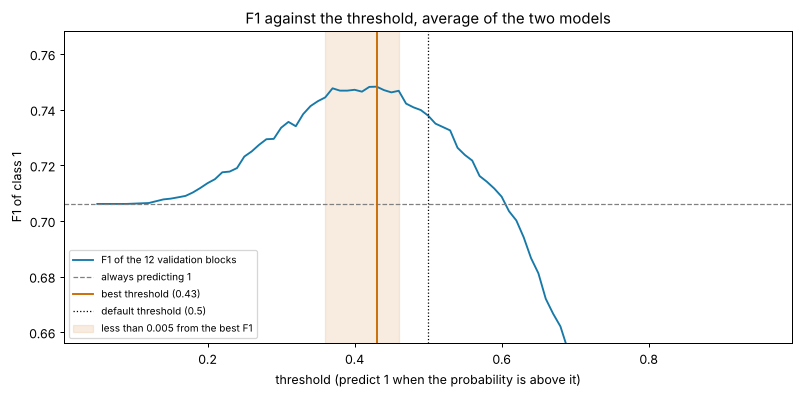

,0,1,2,3,4,5,6,7,8,9,10,11
F1 at the threshold,0.736,0.722,0.776,0.765,0.736,0.748,0.759,0.755,0.754,0.709,0.771,0.752
F1 at 0.5,0.768,0.715,0.798,0.745,0.721,0.737,0.759,0.743,0.754,0.679,0.718,0.736
F1 always 1,0.696,0.701,0.682,0.688,0.732,0.756,0.735,0.690,0.700,0.609,0.720,0.747


In [12]:
curve = f1_curve(final_probs)
threshold = curve.idxmax()
near_best = curve[curve >= curve.max() - 0.005].index

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(curve.index, curve.values, color="#1779A8", label="F1 of the 12 validation blocks")
ax.axhline(floor_f1, color="grey", linestyle="--", linewidth=1, label="always predicting 1")
ax.axvline(threshold, color="#C96A00", linewidth=1.5, label=f"best threshold ({threshold})")
ax.axvline(0.5, color="black", linestyle=":", linewidth=1, label="default threshold (0.5)")
ax.axvspan(near_best.min(), near_best.max(), color="#C96A00", alpha=0.12, label="less than 0.005 from the best F1")
ax.set(xlabel="threshold (predict 1 when the probability is above it)", ylabel="F1 of class 1",
       title="F1 against the threshold, average of the two models")
ax.set_ylim(floor_f1 - 0.05, curve.max() + 0.02)
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

per_block = pd.DataFrame({"F1 at the threshold": [f1_score(y, p >= threshold) for y, p in zip(y_blocks, final_probs)],
                          "F1 at 0.5": [f1_score(y, p >= 0.5) for y, p in zip(y_blocks, final_probs)],
                          "F1 always 1": [f1_score(y, np.ones(len(y))) for y in y_blocks]})
print(f"Threshold: {threshold} | F1: {curve.max():.3f} (at 0.5: {curve[0.5]:.3f}, always 1: {floor_f1:.3f})")
print(f"Thresholds within 0.005 of the best F1: {near_best.min()} to {near_best.max()}")
print(f"Blocks where the model beats always predicting 1: {(per_block['F1 at the threshold'] > per_block['F1 always 1']).sum()}/12")
per_block.round(3).T

The best threshold is 0.43, below 0.5. For the F1 of class 1, missing a repeat purchase costs more than predicting one that does not happen, so it pays to predict 1 a bit more often. The curve is flat around the best point (from 0.36 to 0.46 the F1 changes by less than 0.005), so the exact value matters little, but 0.5 is already outside this zone.

With this threshold the model reaches an F1 of 0.748 against 0.706 for always predicting 1, and it beats it in 11 of the 12 blocks. The only exception is a block where always predicting 1 is already very strong (0.756), because most of its purchases come back.

### **34. Holdout Check**

The holdout is the most recent part of train.csv (2024 and 2025, section 12.1). No decision of Parts 2 to 4 used it: the model, the settings and the threshold were all chosen with the 12 splits. So it is the honest test of the whole recipe, on purchases closer to the period of test.csv. Both models learn from the development rows only (2015 to 2023), and the threshold stays 0.43.

In [13]:
dev_rows, holdout_rows = df_model.index[is_dev], df_model.index[~is_dev]
pipes = fit_average(dev_rows)                     # both models learn only from the development rows
p_holdout = predict_average(pipes, df_model.loc[holdout_rows])
y_holdout = df_model.loc[holdout_rows, target_col].to_numpy()

print(f"Holdout: {len(holdout_rows)} purchases (2024-2025) | repeat rate: {y_holdout.mean():.3f}")
print(f"AP: {average_precision_score(y_holdout, p_holdout):.3f}")
print(f"F1 at the threshold ({threshold}): {f1_score(y_holdout, p_holdout >= threshold):.3f}"
      f" | at 0.5: {f1_score(y_holdout, p_holdout >= 0.5):.3f} | always 1: {f1_score(y_holdout, np.ones(len(y_holdout))):.3f}")
print(f"Purchases predicted as 1: {(p_holdout >= threshold).mean():.0%}")
pd.DataFrame(confusion_matrix(y_holdout, p_holdout >= threshold),
             index=["no repeat (0)", "repeat (1)"], columns=["predicted 0", "predicted 1"])

Holdout: 835 purchases (2024-2025) | repeat rate: 0.605
AP: 0.864
F1 at the threshold (0.43): 0.789 | at 0.5: 0.778 | always 1: 0.754
Purchases predicted as 1: 70%


,predicted 0,predicted 1
no repeat (0),177,153
repeat (1),76,429


On the holdout the model reaches an **F1 of 0.789**, against 0.754 for always predicting 1, and an AP of 0.864. The gain over the floor (+0.035) is close to the one of the 12 blocks (+0.042), so the choices of Part 4 were not too optimistic. The threshold of 0.43 is also better than 0.5 here (0.789 against 0.778).

The values are higher than in the 12 blocks because the repeat rate of the holdout is higher (0.605): when more purchases come back, the F1 of class 1 is easier, also for the floor. The confusion matrix shows the cost of the threshold: the model finds most of the repeat purchases (429 of 505), and in exchange about half of the purchases that do not come back are predicted as 1.

### **35. Final Model and Submission**

The final model is the same average of the two models, now fitted on all the 6,469 purchases of train.csv: the development rows and the holdout. The most recent purchases are the closest to test.csv, so the model should learn from them too. Then test.csv follows the path of 21.4: `prepare_data` (Layer A, row by row), and the fitted pipelines only transform it, they never learn from it. The threshold stays 0.43, as chosen in section 33.

In [14]:
# the final model learns from all the 6,469 purchases of train.csv: development rows and holdout
final_pipes = fit_average(df_model.index)

# test.csv goes through the same Layer A, and the pipeline only transforms it (never fit)
test_path = os.path.join("..", "data", "raw", "test.csv")
df_test = pd.read_csv(test_path, index_col="ID", sep=",")
test_model = prepare_data(df_test, df_clientes)
p_test = predict_average(final_pipes, test_model)

submission = pd.DataFrame({"ID": test_model.index, target_col: (p_test >= threshold).astype(int)})
sample = pd.read_csv(os.path.join("..", "data", "raw", "sample_submission.csv"))
print(f"Test purchases: {len(submission):,} | same IDs and order as sample_submission.csv: {submission['ID'].equals(sample['ID'])}")
print(f"Purchases predicted as 1: {submission[target_col].mean():.0%} (holdout: {(p_holdout >= threshold).mean():.0%})")

os.makedirs(os.path.join("..", "data", "processed"), exist_ok=True)
submission.to_csv(os.path.join("..", "data", "processed", "submission_group44.csv"), index=False)
submission.head()

Test purchases: 986 | same IDs and order as sample_submission.csv: True
Purchases predicted as 1: 73% (holdout: 70%)


,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,1
3,10000020,0
4,10000025,1


test.csv has 986 purchases, with the same IDs and in the same order as `sample_submission.csv`. The model predicts 1 for 73% of them, close to the 70% of the holdout, so test.csv does not look very different from the most recent purchases of train.csv. The file is saved as `submission_group44.csv` in `data/processed`.

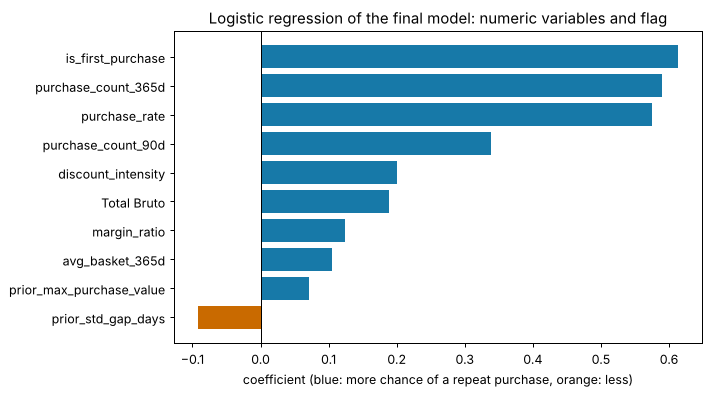

In [15]:
# what the logistic regression of the final model learned: the coefficients of the numeric variables
# (scaled, so they can be compared) and of the flag
lr_pipe = final_pipes[0]
prep = lr_pipe.named_steps["prep"]
names = []
for name, steps, cols in prep.transformers_:
    if name == "cat":
        names += list(steps.named_steps["encode"].get_feature_names_out(cols))
    elif name != "remainder":
        names += list(cols)
coefs = pd.Series(lr_pipe.named_steps["model"].coef_[0], index=names)
numeric = coefs[[n for n in names if n in selected]].sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(numeric.index, numeric.values, color=np.where(numeric > 0, "#1779A8", "#C96A00"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="coefficient (blue: more chance of a repeat purchase, orange: less)",
       title="Logistic regression of the final model: numeric variables and flag")
plt.tight_layout()
plt.show()

The coefficients of the logistic regression show what the model learned (for the numeric variables they are comparable, because the columns are scaled). The frequency is the strongest signal: `purchase_count_365d`, `purchase_rate` and `purchase_count_90d`. A client who buys more often, and recently, comes back more. The discounts, the value of the invoice and the margin add a little. `prior_std_gap_days` is the only negative one: a client with irregular gaps between purchases comes back less.

`is_first_purchase` has a big positive coefficient, which looks strange after 7.3 (first purchases come back less). But the flag never acts alone: in a first purchase all the counts are 0, and they push the probability down a lot. The flag corrects part of this, because a new client is not the same as an old client who stopped buying. Together, first purchases still get a low probability.

### **36. Summary of Part 4**

| Section | Decision | Options tested | Choice | Why |
|---|---|---|---|---|
| 29 | Models | – | logistic regression and gradient boosting | a linear model that follows the monotonic relations of the EDA, and the strongest family for tables |
| 30 | Variables | final set of Part 3, all the 48 candidates | final set for the logistic regression, all the candidates for gradient boosting | best AP of each model |
| 31.1 | Penalty of the logistic regression | C from 0.01 to 3 | C = 0.1 | best AP, all values very close |
| 31.2 | Settings of gradient boosting | 5 settings, from the default to small trees | 4 leaves, learning rate 0.03, 80 rows per leaf, 400 trees | the default overfits; small trees are clearly better |
| 32 | Final model | logistic regression, gradient boosting, average of the two | average of the two | the only option outside the noise (better in 11 of 12 blocks) |
| 33 | Threshold | 0.05 to 0.95 | 0.43 | best F1 of the 12 blocks; the curve is flat around it |
| 34 | Holdout check | – | F1 0.789 against 0.754 for always 1 | the gain is close to the one of the 12 blocks |
| 35 | Submission | – | fitted on all train.csv, `submission_group44.csv` | the most recent purchases are the closest to test.csv |

The main lesson of Part 4 is the same as in Parts 2 and 3: this data rewards simple models. The strong signals are few (frequency, recency and value of the client) and they add up, so a logistic regression with 12 variables already gets most of the result, and gradient boosting only works with small trees. Most of the gain over always predicting 1 comes from the threshold and from the average of two models that make different mistakes.